**DUBOKO UČENJE LV1**

In [2]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import medmnist
from medmnist import BloodMNIST, INFO

# Odabiremo GPU ako je dostupan, inače CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("MedMNIST:", medmnist.__version__)
print("Uređaj za računanje:", device)

if device.type == "cuda":
    print("Grafička kartica:", torch.cuda.get_device_name(0))
else:
    print("GPU nije dostupan u ovom Python okruženju.")

Python: 3.12.10
PyTorch: 2.11.0+cu128
MedMNIST: 3.0.2
Uređaj za računanje: cuda
Grafička kartica: NVIDIA GeForce RTX 3050 Laptop GPU


In [4]:
# Podaci će se spremiti u mapu "podaci" unutar trenutačne radne mape.
data_dir = Path.cwd() / "podaci"
data_dir.mkdir(parents=True, exist_ok=True)

print("Mapa za podatke:", data_dir)

# Koristimo službenu podjelu podataka.
# Pri prvom pokretanju download=True preuzima podatke.
train_dataset = BloodMNIST(
    split="train",
    root=str(data_dir),
    size=28,
    download=True
)

val_dataset = BloodMNIST(
    split="val",
    root=str(data_dir),
    size=28,
    download=True
)

test_dataset = BloodMNIST(
    split="test",
    root=str(data_dir),
    size=28,
    download=True
)

# Nazive klasa čitamo iz službenih metapodataka.
info = INFO["bloodmnist"]
class_names = [
    info["label"][str(i)]
    for i in range(len(info["label"]))
]

datasets = {
    "Treniranje": train_dataset,
    "Validacija": val_dataset,
    "Testiranje": test_dataset
}

# Dimenzije i broj primjera čitamo iz učitanih podataka.
for name, dataset in datasets.items():
    print(f"\n{name}:")
    print("  Broj slika:", len(dataset))
    print("  Oblik polja slika:", dataset.imgs.shape)
    print("  Oblik jedne slike:", dataset.imgs[0].shape)
    print("  Oblik polja oznaka:", dataset.labels.shape)

print("\nUkupan broj slika:", sum(len(ds) for ds in datasets.values()))
print("Broj klasa prema metapodacima:", len(class_names))

print("\nOznake i nazivi klasa:")
for label, name in enumerate(class_names):
    print(f"  {label}: {name}")

Mapa za podatke: c:\Users\PC\Documents\ferit\DRB_1g\DUBOKO UČENJE\podaci

Treniranje:
  Broj slika: 11959
  Oblik polja slika: (11959, 28, 28, 3)
  Oblik jedne slike: (28, 28, 3)
  Oblik polja oznaka: (11959, 1)

Validacija:
  Broj slika: 1712
  Oblik polja slika: (1712, 28, 28, 3)
  Oblik jedne slike: (28, 28, 3)
  Oblik polja oznaka: (1712, 1)

Testiranje:
  Broj slika: 3421
  Oblik polja slika: (3421, 28, 28, 3)
  Oblik jedne slike: (28, 28, 3)
  Oblik polja oznaka: (3421, 1)

Ukupan broj slika: 17092
Broj klasa prema metapodacima: 8

Oznake i nazivi klasa:
  0: basophil
  1: eosinophil
  2: erythroblast
  3: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
  4: lymphocyte
  5: monocyte
  6: neutrophil
  7: platelet


Klasa                                                 Treniranje  Validacija  Testiranje    Ukupno
--------------------------------------------------------------------------------------------------
basophil                                                     852         122         244      1218
eosinophil                                                  2181         312         624      3117
erythroblast                                                1085         155         311      1551
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)        2026         290         579      2895
lymphocyte                                                   849         122         243      1214
monocyte                                                     993         143         284      1420
neutrophil                                                  2330         333         666      3329
platelet                                                    1643         235         470      

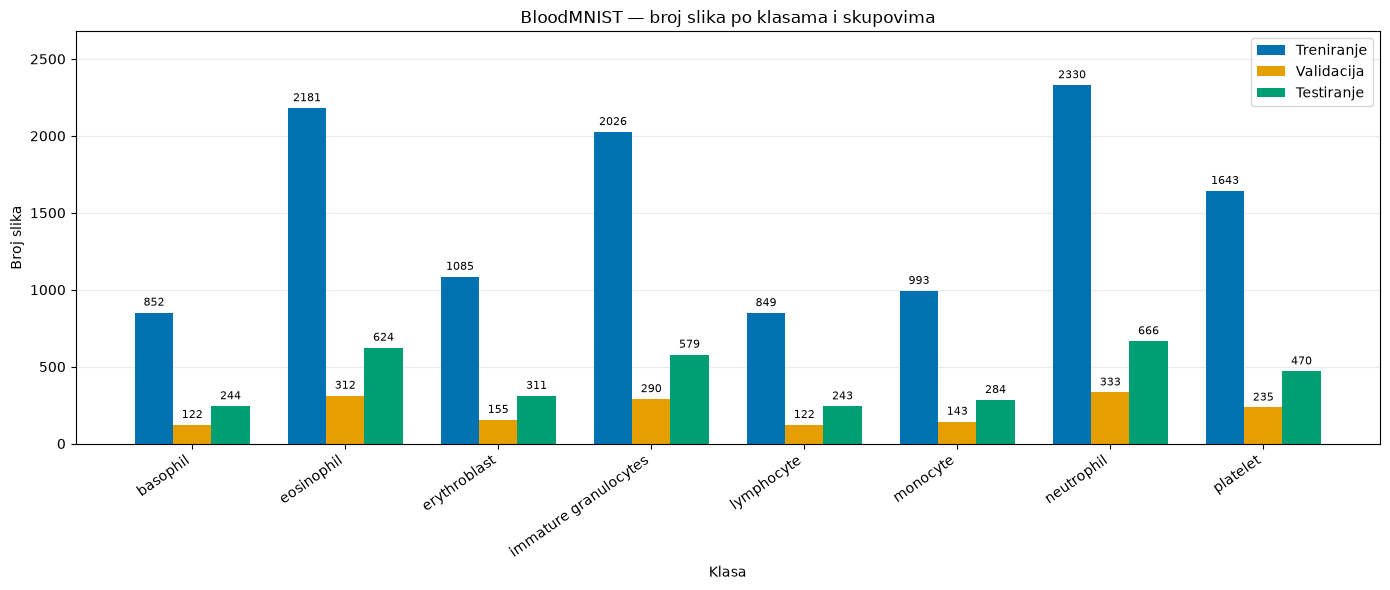

In [ ]:
# Broj klasa čitamo iz prethodno učitanih metapodataka.
n_classes = len(class_names)

# Za svaki skup spremamo broj slika u svakoj klasi.
class_counts = {}

for split_name, dataset in datasets.items():
    # Oznake oblika (N, 1) pretvaramo u jednodimenzionalni niz (N,).
    labels = dataset.labels.flatten()

    # Brojimo koliko se puta pojavljuje svaka oznaka: 0, 1, ..., 7.
    counts = np.bincount(labels, minlength=n_classes)
    class_counts[split_name] = counts

# Ispis tablice s brojevima iz stvarnih podataka.
print(
    f"{'Klasa':<52}"
    f"{'Treniranje':>12}"
    f"{'Validacija':>12}"
    f"{'Testiranje':>12}"
    f"{'Ukupno':>10}"
)
print("-" * 98)

for i, class_name in enumerate(class_names):
    train_count = class_counts["Treniranje"][i]
    val_count = class_counts["Validacija"][i]
    test_count = class_counts["Testiranje"][i]

    print(
        f"{class_name:<52}"
        f"{train_count:>12}"
        f"{val_count:>12}"
        f"{test_count:>12}"
        f"{train_count + val_count + test_count:>10}"
    )

# Kraći prikaz jednog dugog naziva radi čitljivosti grafa.
plot_names = [
    name.replace(
        "immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",
        "immature granulocytes"
    )
    for name in class_names
]

# Položaji osam klasa na vodoravnoj osi.
x = np.arange(n_classes)
width = 0.25
colors = ["#0072B2", "#E69F00", "#009E73"]

fig, ax = plt.subplots(figsize=(14, 6))

for j, (split_name, counts) in enumerate(class_counts.items()):
    bars = ax.bar(
        x + (j - 1) * width,
        counts,
        width=width,
        label=split_name,
        color=colors[j]
    )

    # Iznad svakog stupca ispisujemo broj slika.
    ax.bar_label(bars, padding=3, fontsize=8)

ax.set_title("BloodMNIST — broj slika po klasama i skupovima")
ax.set_xlabel("Klasa")
ax.set_ylabel("Broj slika")
ax.set_xticks(x)
ax.set_xticklabels(plot_names, rotation=35, ha="right")
ax.legend()
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

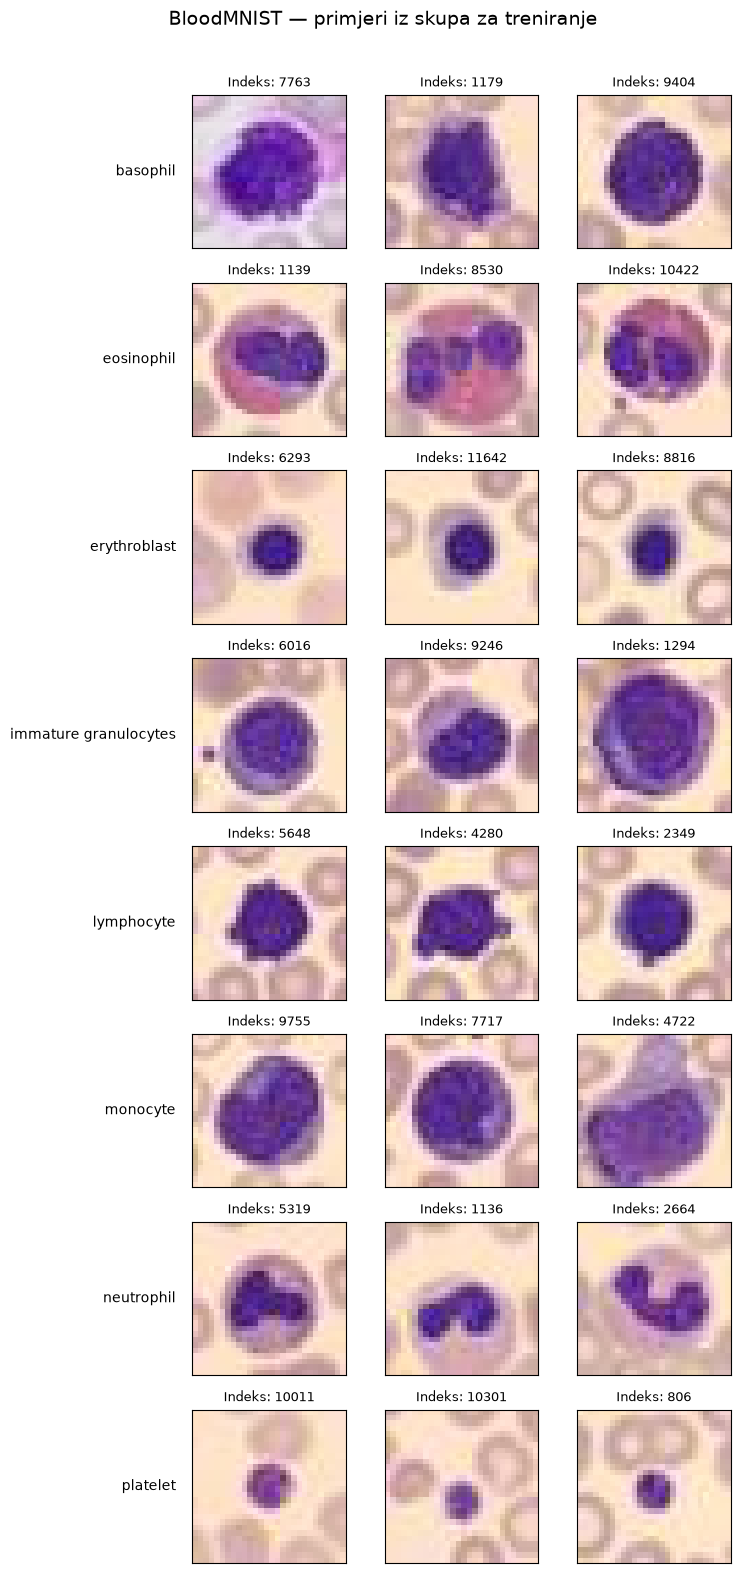

In [6]:
# Fiksni seed omogućuje da pri ponovnom pokretanju
# dobijemo isti nasumični izbor slika.
rng = np.random.default_rng(seed=42)

images_per_class = 3
train_labels = train_dataset.labels.flatten()

# Svaki red predstavlja jednu klasu, a svaki stupac jedan primjer.
fig, axes = plt.subplots(
    nrows=n_classes,
    ncols=images_per_class,
    figsize=(8, 2 * n_classes),
    squeeze=False
)

for class_id, class_name in enumerate(plot_names):
    # Pronalazimo indekse slika koje pripadaju toj klasi.
    class_indices = np.flatnonzero(train_labels == class_id)

    # Biramo tri različite slike iz te klase.
    selected_indices = rng.choice(
        class_indices,
        size=images_per_class,
        replace=False
    )

    for column, image_index in enumerate(selected_indices):
        ax = axes[class_id, column]

        ax.imshow(train_dataset.imgs[image_index])
        ax.set_title(f"Indeks: {image_index}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

        # Naziv klase ispisujemo uz prvu sliku svakog reda.
        if column == 0:
            ax.set_ylabel(
                class_name,
                rotation=0,
                ha="right",
                va="center",
                labelpad=12
            )

fig.suptitle("BloodMNIST — primjeri iz skupa za treniranje", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [7]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Pretvara sliku u PyTorch tensor:
# - oblik (visina, širina, kanali) mijenja u (kanali, visina, širina)
# - vrijednosti piksela iz raspona 0–255 pretvara u raspon 0–1
transform = transforms.ToTensor()

# Transformacija će se primijeniti kada dohvatimo pojedinu sliku.
for dataset in datasets.values():
    dataset.transform = transform

batch_size = 64

# Trening podatke miješamo kako redoslijed ne bi bio uvijek isti.
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

# Za validaciju i testiranje ne trebamo miješati redoslijed.
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Dohvaćamo jedan batch kako bismo provjerili pripremu.
images, labels = next(iter(train_loader))

# BloodMNIST vraća oznake oblika (batch, 1).
# Za klasifikacijski gubitak trebamo oblik (batch,) i tip long.
labels = labels.squeeze(1).long()

print("Oblik batcha slika:", images.shape)
print("Tip podataka slika:", images.dtype)
print("Najmanja vrijednost piksela:", images.min().item())
print("Najveća vrijednost piksela:", images.max().item())
print("Oblik oznaka:", labels.shape)
print("Tip podataka oznaka:", labels.dtype)

print("\nBroj batcheva:")
print("Treniranje:", len(train_loader))
print("Validacija:", len(val_loader))
print("Testiranje:", len(test_loader))

Oblik batcha slika: torch.Size([64, 3, 28, 28])
Tip podataka slika: torch.float32
Najmanja vrijednost piksela: 0.04313725605607033
Najveća vrijednost piksela: 1.0
Oblik oznaka: torch.Size([64])
Tip podataka oznaka: torch.int64

Broj batcheva:
Treniranje: 187
Validacija: 27
Testiranje: 54


In [13]:
import torch.nn as nn

# Fiksiramo početno nasumično postavljanje parametara.
torch.manual_seed(42)


class BloodCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # Izdvajanje značajki iz slika.
        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Klasifikacija na temelju izdvojenih značajki.
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Stvaramo mrežu i prebacujemo njezine parametre na GPU.
model = BloodCNN(num_classes=n_classes).to(device)

print(model)

num_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"\nBroj parametara koji se uče: {num_parameters:,}")
print("Uređaj modela:", next(model.parameters()).device)

# Provjera oblika izlaza, bez treniranja i računanja gradijenata.
with torch.no_grad():
    sample_outputs = model(images.to(device))

print("Oblik ulaznog batcha:", images.shape)
print("Oblik izlaza mreže:", sample_outputs.shape)

BloodCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)

Broj parametara koji se uče: 206,952
Uređaj modela: cuda:0
Oblik ulaznog batcha: torch.Size([64, 3, 28, 28])
Oblik izlaza mreže: torch.Size([64, 8])


In [14]:
# Funkcija gubitka za klasifikaciju:
# svaka slika pripada točno jednoj od 8 klasa.
criterion = nn.CrossEntropyLoss()

# Stopa učenja određuje veličinu koraka pri ažuriranju parametara.
learning_rate = 0.001

# Adam ažurira parametre mreže koristeći njihove gradijente.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

print("Funkcija gubitka:", criterion)
print("Optimizator:", type(optimizer).__name__)
print("Stopa učenja:", learning_rate)

Funkcija gubitka: CrossEntropyLoss()
Optimizator: Adam
Stopa učenja: 0.001


In [10]:
def train_one_epoch(model, data_loader, criterion, optimizer, device):
    # Uključujemo način rada za treniranje.
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in data_loader:
        # Slike i oznake prebacujemo na isti uređaj kao mrežu.
        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        # Brišemo gradijente prethodnog koraka.
        optimizer.zero_grad(set_to_none=True)

        # 1. Mreža izračunava rezultate za slike iz batcha.
        outputs = model(images)

        # 2. Uspoređujemo rezultate s točnim oznakama.
        loss = criterion(outputs, labels)

        # 3. Računamo gradijente parametara.
        loss.backward()

        # 4. Ažuriramo parametre mreže.
        optimizer.step()

        # Klasa s najvećom izlaznom vrijednošću je predviđena klasa.
        predictions = outputs.argmax(dim=1)

        # Prikupljamo podatke za prosjek cijele epohe.
        current_batch_size = images.size(0)

        total_loss += loss.item() * current_batch_size
        total_correct += (predictions == labels).sum().item()
        total_samples += current_batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

In [11]:
def evaluate(model, data_loader, criterion, device):
    # Postavljamo mrežu u način rada za evaluaciju.
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    # Gradijenti nam nisu potrebni jer ne ažuriramo parametre.
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.squeeze(1).long().to(device)

            # Predviđanja mreže i izračun gubitka.
            outputs = model(images)
            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            # Prikupljamo rezultate svih batcheva.
            current_batch_size = images.size(0)

            total_loss += loss.item() * current_batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += current_batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

In [15]:
import time

num_epochs = 50

# Mapa za spremanje najboljeg modela.
results_dir = Path.cwd() / "rezultati"
results_dir.mkdir(parents=True, exist_ok=True)

best_model_path = results_dir / "bloodcnn_best.pt"

# Ovdje bilježimo rezultate za kasnije crtanje grafova.
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "epoch_seconds": []
}

best_val_loss = float("inf")
best_epoch = 0

for epoch in range(1, num_epochs + 1):
    # GPU radi asinkrono: čekamo završetak prethodnih operacija
    # kako bi mjerenje vremena bilo ispravno.
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["epoch_seconds"].append(elapsed)

    # Spremamo težine kada se validacijski gubitak poboljša.
    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), best_model_path)

    status = " | spremljen najbolji model" if improved else ""

    print(
        f"Epoha {epoch:02d}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.2%} | "
        f"val acc: {val_accuracy:.2%} | "
        f"{elapsed:.1f} s"
        f"{status}",
        flush=True
    )

# Vraćamo najbolje spremljene težine, a ne nužno one iz zadnje epohe.
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

print(f"\nNajbolja epoha: {best_epoch}")
print(f"Najmanji validacijski gubitak: {best_val_loss:.4f}")
print(f"Vrijeme treniranja i validacije: "
      f"{sum(history['epoch_seconds']):.1f} s")
print("Najbolji model spremljen u:", best_model_path)

Epoha 01/50 | train loss: 1.2659 | val loss: 0.8662 | train acc: 52.70% | val acc: 71.03% | 3.5 s | spremljen najbolji model
Epoha 02/50 | train loss: 0.8030 | val loss: 0.7040 | train acc: 71.82% | val acc: 74.47% | 2.3 s | spremljen najbolji model
Epoha 03/50 | train loss: 0.6756 | val loss: 0.5930 | train acc: 76.17% | val acc: 79.38% | 2.0 s | spremljen najbolji model
Epoha 04/50 | train loss: 0.5828 | val loss: 0.4892 | train acc: 79.40% | val acc: 82.94% | 2.2 s | spremljen najbolji model
Epoha 05/50 | train loss: 0.5220 | val loss: 0.4471 | train acc: 81.16% | val acc: 83.76% | 2.3 s | spremljen najbolji model
Epoha 06/50 | train loss: 0.4707 | val loss: 0.4444 | train acc: 83.11% | val acc: 83.76% | 3.5 s | spremljen najbolji model
Epoha 07/50 | train loss: 0.4290 | val loss: 0.4400 | train acc: 84.27% | val acc: 83.35% | 4.4 s | spremljen najbolji model
Epoha 08/50 | train loss: 0.4133 | val loss: 0.3940 | train acc: 85.32% | val acc: 85.69% | 4.8 s | spremljen najbolji model


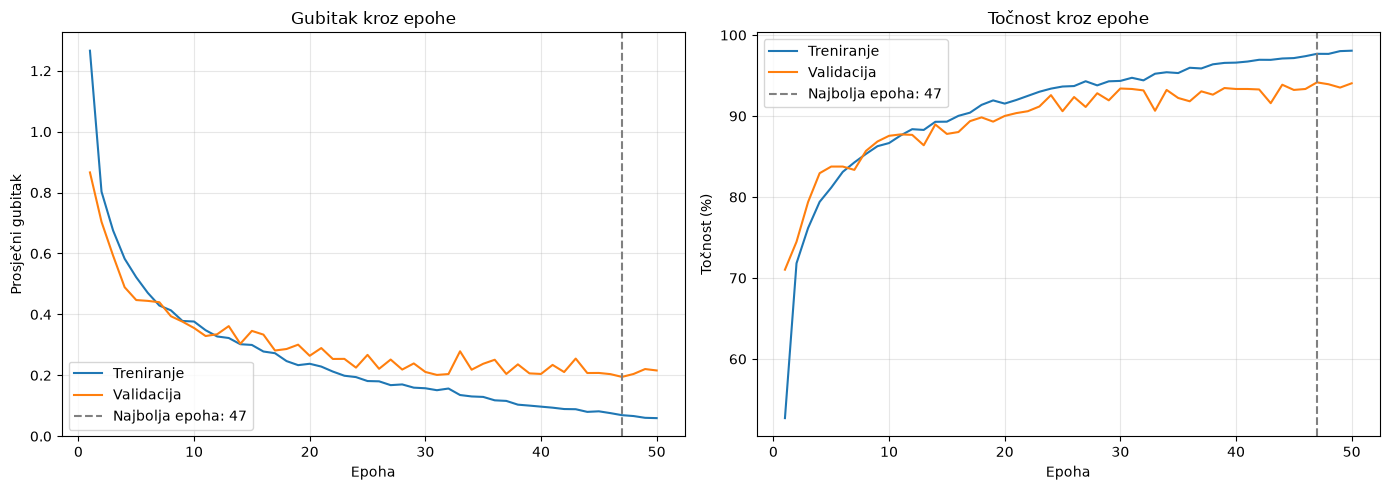

Najbolja epoha: 47
Trening gubitak: 0.0691
Validacijski gubitak: 0.1948
Trening točnost: 97.68%
Validacijska točnost: 94.16%
Graf spremljen u: c:\Users\PC\Documents\ferit\DRB_1g\DUBOKO UČENJE\rezultati\tijek_treniranja.png


In [16]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Lijevi graf: prosječni gubitak.
axes[0].plot(
    epochs, history["train_loss"],
    label="Treniranje"
)
axes[0].plot(
    epochs, history["val_loss"],
    label="Validacija"
)
axes[0].axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Najbolja epoha: {best_epoch}"
)
axes[0].set_title("Gubitak kroz epohe")
axes[0].set_xlabel("Epoha")
axes[0].set_ylabel("Prosječni gubitak")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Desni graf: točnost izražena u postocima.
axes[1].plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    label="Treniranje"
)
axes[1].plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    label="Validacija"
)
axes[1].axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Najbolja epoha: {best_epoch}"
)
axes[1].set_title("Točnost kroz epohe")
axes[1].set_xlabel("Epoha")
axes[1].set_ylabel("Točnost (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Spremamo graf prije prikaza.
graph_path = results_dir / "tijek_treniranja.png"
fig.savefig(graph_path, dpi=200, bbox_inches="tight")

plt.show()

# Rezultati epohe odabrane prema najmanjem validacijskom gubitku.
best_index = best_epoch - 1

print(f"Najbolja epoha: {best_epoch}")
print(f"Trening gubitak: {history['train_loss'][best_index]:.4f}")
print(f"Validacijski gubitak: {history['val_loss'][best_index]:.4f}")
print(f"Trening točnost: {history['train_accuracy'][best_index]:.2%}")
print(f"Validacijska točnost: {history['val_accuracy'][best_index]:.2%}")
print("Graf spremljen u:", graph_path)

In [17]:
import json
import shutil
from datetime import datetime

# Svaki pokus dobiva zasebnu mapu.
experiment_dir = (
    results_dir
    / f"osnovni_cnn_model"
)
experiment_dir.mkdir(parents=True, exist_ok=False)

# Kopiramo datoteku s najboljim težinama osnovnog modela.
shutil.copy2(
    best_model_path,
    experiment_dir / "best_model.pt"
)

# Spremamo rezultate svih epoha i podatke o pokusu.
experiment_results = {
    "history": history,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "num_epochs": len(history["train_loss"]),
    "batch_size": train_loader.batch_size,
    "learning_rate": learning_rate,
    "augmentation": False,
    "model_architecture": str(model),
    "pytorch_version": str(torch.__version__)
}

with open(
    experiment_dir / "rezultati.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        experiment_results,
        file,
        ensure_ascii=False,
        indent=2
    )

print("Osnovni model i rezultati spremljeni u:")
print(experiment_dir)

Osnovni model i rezultati spremljeni u:
c:\Users\PC\Documents\ferit\DRB_1g\DUBOKO UČENJE\rezultati\osnovni_cnn_model


In [41]:
# Transformacije za trening:
# nasumično zrcaljenje i blaga rotacija, zatim pretvaranje u tensor.
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1),
    transforms.ToTensor()
])

train_dataset.transform = train_transform

# Validacijske i testne slike ne mijenjamo nasumično.
eval_transform = transforms.ToTensor()

val_dataset.transform = eval_transform
test_dataset.transform = eval_transform

print("Treniranje:", train_dataset.transform)
print("\nValidacija i testiranje:", eval_transform)

Treniranje: Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=None, saturation=None, hue=None)
    ToTensor()
)

Validacija i testiranje: ToTensor()


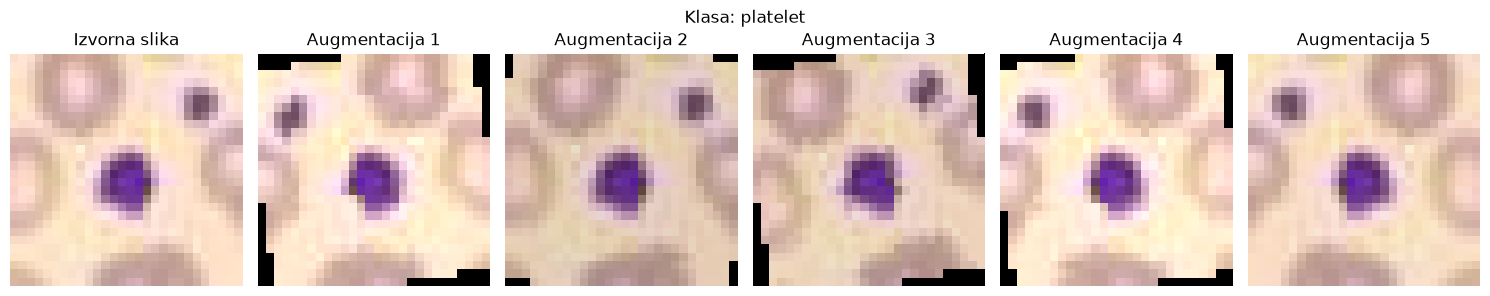

In [42]:
# Odabiremo jednu sliku iz trening skupa.
image_index = 0

original_image = train_dataset.imgs[image_index]
class_id = int(train_dataset.labels[image_index].item())

fig, axes = plt.subplots(1, 6, figsize=(15, 3))

# Izvorna slika, bez transformacija.
axes[0].imshow(original_image)
axes[0].set_title("Izvorna slika")
axes[0].axis("off")

# Svako dohvaćanje iste slike ponovno primjenjuje
# nasumične transformacije.
for i in range(1, 6):
    augmented_image, _ = train_dataset[image_index]

    # Tensor ima oblik (C, H, W).
    # Matplotlib za prikaz očekuje oblik (H, W, C).
    image_for_display = augmented_image.permute(1, 2, 0).numpy()

    axes[i].imshow(image_for_display)
    axes[i].set_title(f"Augmentacija {i}")
    axes[i].axis("off")

fig.suptitle(f"Klasa: {class_names[class_id]}")
plt.tight_layout()
plt.show()

In [43]:
# Isti seed kao pri stvaranju osnovnog modela.
torch.manual_seed(42)

# Nova mreža s početnim parametrima.
model = BloodCNN(num_classes=n_classes).to(device)

# Ista funkcija gubitka i stopa učenja kao prije.
criterion = nn.CrossEntropyLoss()
learning_rate = 0.001

# Novi optimizator povezan s novom mrežom.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

print("Nova mreža spremna za treniranje.")
print("Uređaj:", next(model.parameters()).device)
print("Stopa učenja:", learning_rate)
print("\nAktivne trening transformacije:")
print(train_dataset.transform)

Nova mreža spremna za treniranje.
Uređaj: cuda:0
Stopa učenja: 0.001

Aktivne trening transformacije:
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=None, saturation=None, hue=None)
    ToTensor()
)


In [44]:
import json
import time

# Čitamo broj epoha osnovnog pokusa radi usporedbe.
baseline_dir = results_dir / "osnovni_cnn_model"

with open(
    baseline_dir / "rezultati.json",
    "r",
    encoding="utf-8"
) as file:
    baseline_results = json.load(file)

num_epochs = baseline_results["num_epochs"]

# Zasebna datoteka za najbolji model s augmentacijom.
best_model_path = results_dir / "bloodcnn_augmentacija_best.pt"

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "epoch_seconds": []
}

best_val_loss = float("inf")
best_epoch = 0

print(f"Broj epoha: {num_epochs}")
print("Trening transformacije:", train_dataset.transform)

for epoch in range(1, num_epochs + 1):
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["epoch_seconds"].append(elapsed)

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), best_model_path)

    status = " | spremljen najbolji model" if improved else ""

    print(
        f"Epoha {epoch:02d}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.2%} | "
        f"val acc: {val_accuracy:.2%} | "
        f"{elapsed:.1f} s"
        f"{status}",
        flush=True
    )

# Vraćamo težine s najmanjim validacijskim gubitkom.
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

# Spremamo povijest i postavke ovog pokusa.
augmentation_results = {
    "history": history,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "num_epochs": num_epochs,
    "batch_size": train_loader.batch_size,
    "learning_rate": learning_rate,
    "augmentation": str(train_dataset.transform),
    "model_architecture": str(model),
    "pytorch_version": str(torch.__version__)
}

with open(
    results_dir / "rezultati_augmentacija.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        augmentation_results,
        file,
        ensure_ascii=False,
        indent=2
    )

print(f"\nNajbolja epoha: {best_epoch}")
print(f"Najmanji validacijski gubitak: {best_val_loss:.4f}")
print(
    "Validacijska točnost te epohe:",
    f"{history['val_accuracy'][best_epoch - 1]:.2%}"
)
print("Model spremljen u:", best_model_path)

Broj epoha: 50
Trening transformacije: Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=None, saturation=None, hue=None)
    ToTensor()
)
Epoha 01/50 | train loss: 1.2736 | val loss: 0.8655 | train acc: 52.25% | val acc: 68.93% | 7.7 s | spremljen najbolji model
Epoha 02/50 | train loss: 0.8045 | val loss: 0.7019 | train acc: 71.74% | val acc: 75.35% | 10.3 s | spremljen najbolji model
Epoha 03/50 | train loss: 0.6747 | val loss: 0.5853 | train acc: 76.56% | val acc: 79.96% | 12.1 s | spremljen najbolji model
Epoha 04/50 | train loss: 0.5810 | val loss: 0.4939 | train acc: 79.50% | val acc: 82.24% | 12.5 s | spremljen najbolji model
Epoha 05/50 | train loss: 0.5275 | val loss: 0.4645 | train acc: 81.41% | val acc: 82.30% | 12.6 s | spremljen najbolji model
Epoha 06/50 | train loss: 0.4933 | val loss: 0.5139 | train acc: 81.91% | val acc: 79.91% | 12.8 s
Epoha 0

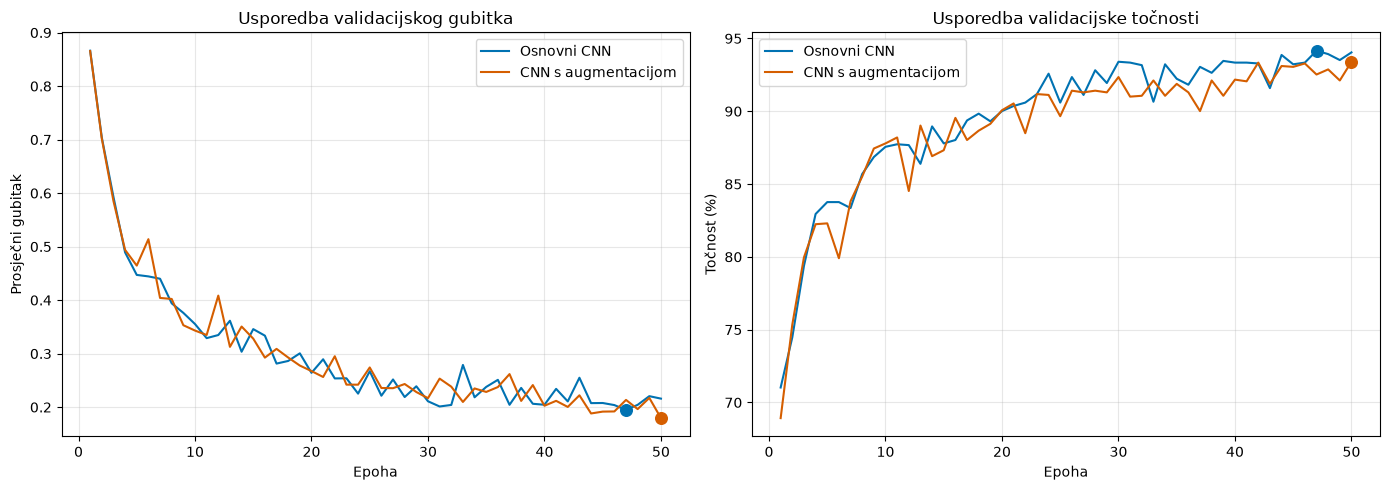

Model                     Najbolja epoha    Val. gubitak    Val. točnost
Osnovni CNN                           47          0.1948         94.16%
CNN s augmentacijom                   50          0.1795         93.40%


In [45]:
import json

# Učitavamo rezultate oba pokusa.
with open(
    results_dir / "osnovni_cnn_model" / "rezultati.json",
    "r",
    encoding="utf-8"
) as file:
    baseline_results = json.load(file)

with open(
    results_dir / "rezultati_augmentacija.json",
    "r",
    encoding="utf-8"
) as file:
    augmentation_results = json.load(file)

experiments = {
    "Osnovni CNN": baseline_results,
    "CNN s augmentacijom": augmentation_results
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#0072B2", "#D55E00"]

for (name, results), color in zip(experiments.items(), colors):
    experiment_history = results["history"]
    epochs = np.arange(1, len(experiment_history["val_loss"]) + 1)

    best_epoch_number = results["best_epoch"]
    best_index = best_epoch_number - 1

    # Validacijski gubitak kroz epohe.
    axes[0].plot(
        epochs,
        experiment_history["val_loss"],
        label=name,
        color=color
    )
    axes[0].scatter(
        best_epoch_number,
        experiment_history["val_loss"][best_index],
        color=color,
        s=70,
        zorder=3
    )

    # Validacijska točnost kroz epohe.
    val_accuracy_percent = (
        np.array(experiment_history["val_accuracy"]) * 100
    )

    axes[1].plot(
        epochs,
        val_accuracy_percent,
        label=name,
        color=color
    )
    axes[1].scatter(
        best_epoch_number,
        val_accuracy_percent[best_index],
        color=color,
        s=70,
        zorder=3
    )

axes[0].set_title("Usporedba validacijskog gubitka")
axes[0].set_ylabel("Prosječni gubitak")

axes[1].set_title("Usporedba validacijske točnosti")
axes[1].set_ylabel("Točnost (%)")

for ax in axes:
    ax.set_xlabel("Epoha")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(
    results_dir / "usporedba_augmentacije.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Uspoređujemo rezultate najboljeg spremljenog modela
# svakog pokusa, odabranog prema validacijskom gubitku.
print(
    f"{'Model':<24}"
    f"{'Najbolja epoha':>16}"
    f"{'Val. gubitak':>16}"
    f"{'Val. točnost':>16}"
)

for name, results in experiments.items():
    index = results["best_epoch"] - 1
    experiment_history = results["history"]

    print(
        f"{name:<24}"
        f"{results['best_epoch']:>16}"
        f"{experiment_history['val_loss'][index]:>16.4f}"
        f"{experiment_history['val_accuracy'][index]:>15.2%}"
    )

In [46]:
# TREĆI POKUS: CNN + augmentacija + cosine annealing

torch.manual_seed(42)

# Nova mreža — treniranje će krenuti od početka.
model = BloodCNN(num_classes=n_classes).to(device)

criterion = nn.CrossEntropyLoss()
learning_rate = 0.001

# Novi optimizator za novu mrežu.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Zadržavamo broj epoha prethodnog pokusa.
num_epochs = augmentation_results["num_epochs"]

# Scheduler upravlja stopom učenja tijekom treniranja.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=0.00001
)

print("Nova mreža spremna.")
print("Uređaj:", next(model.parameters()).device)
print("Broj epoha:", num_epochs)
print("Početna stopa učenja:", optimizer.param_groups[0]["lr"])
print("\nAktivne trening transformacije:")
print(train_dataset.transform)

Nova mreža spremna.
Uređaj: cuda:0
Broj epoha: 50
Početna stopa učenja: 0.001

Aktivne trening transformacije:
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=None, saturation=None, hue=None)
    ToTensor()
)


In [47]:
import time
import json

# Posebna datoteka: prethodni modeli ostaju sačuvani.
best_model_path = results_dir / "bloodcnn_augmentacija_cosine_best.pt"

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "epoch_seconds": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0

for epoch in range(1, num_epochs + 1):
    # Stopa učenja koja će se koristiti u ovoj epohi.
    current_lr = optimizer.param_groups[0]["lr"]

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    # Treniranje na augmentiranim slikama.
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Validacija na neaugmentiranim slikama.
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["epoch_seconds"].append(elapsed)
    history["learning_rate"].append(current_lr)

    # Najbolji model biramo prema validacijskom gubitku.
    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), best_model_path)

    status = " | spremljen najbolji model" if improved else ""

    print(
        f"Epoha {epoch:02d}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.2%} | "
        f"val acc: {val_accuracy:.2%} | "
        f"LR: {current_lr:.8f} | "
        f"{elapsed:.1f} s"
        f"{status}",
        flush=True
    )

    # Nakon završene epohe određujemo stopu za sljedeću.
    scheduler.step()

# Učitavamo najbolje težine ovog pokusa.
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

# Spremamo rezultate za kasniju usporedbu.
cosine_results = {
    "history": history,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "num_epochs": num_epochs,
    "batch_size": train_loader.batch_size,
    "learning_rate": learning_rate,
    "scheduler": "CosineAnnealingLR",
    "T_max": scheduler.T_max,
    "eta_min": scheduler.eta_min,
    "augmentation": str(train_dataset.transform),
    "model_architecture": str(model),
    "pytorch_version": str(torch.__version__)
}

with open(
    results_dir / "rezultati_augmentacija_cosine.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        cosine_results,
        file,
        ensure_ascii=False,
        indent=2
    )

print(f"\nNajbolja epoha: {best_epoch}")
print(f"Najmanji validacijski gubitak: {best_val_loss:.4f}")
print(
    "Validacijska točnost te epohe:",
    f"{history['val_accuracy'][best_epoch - 1]:.2%}"
)
print("Najbolji model spremljen u:", best_model_path)

Epoha 01/50 | train loss: 1.2745 | val loss: 0.8631 | train acc: 52.20% | val acc: 69.22% | LR: 0.00100000 | 10.9 s | spremljen najbolji model
Epoha 02/50 | train loss: 0.8046 | val loss: 0.7018 | train acc: 71.60% | val acc: 75.06% | LR: 0.00099902 | 12.8 s | spremljen najbolji model
Epoha 03/50 | train loss: 0.6757 | val loss: 0.5815 | train acc: 76.58% | val acc: 80.26% | LR: 0.00099610 | 5.9 s | spremljen najbolji model
Epoha 04/50 | train loss: 0.5823 | val loss: 0.4961 | train acc: 79.58% | val acc: 82.07% | LR: 0.00099123 | 5.6 s | spremljen najbolji model
Epoha 05/50 | train loss: 0.5284 | val loss: 0.4661 | train acc: 81.19% | val acc: 82.07% | LR: 0.00098445 | 8.5 s | spremljen najbolji model
Epoha 06/50 | train loss: 0.4931 | val loss: 0.5116 | train acc: 81.93% | val acc: 80.37% | LR: 0.00097577 | 9.8 s
Epoha 07/50 | train loss: 0.4546 | val loss: 0.4066 | train acc: 83.40% | val acc: 83.41% | LR: 0.00096524 | 13.0 s | spremljen najbolji model
Epoha 08/50 | train loss: 0.43

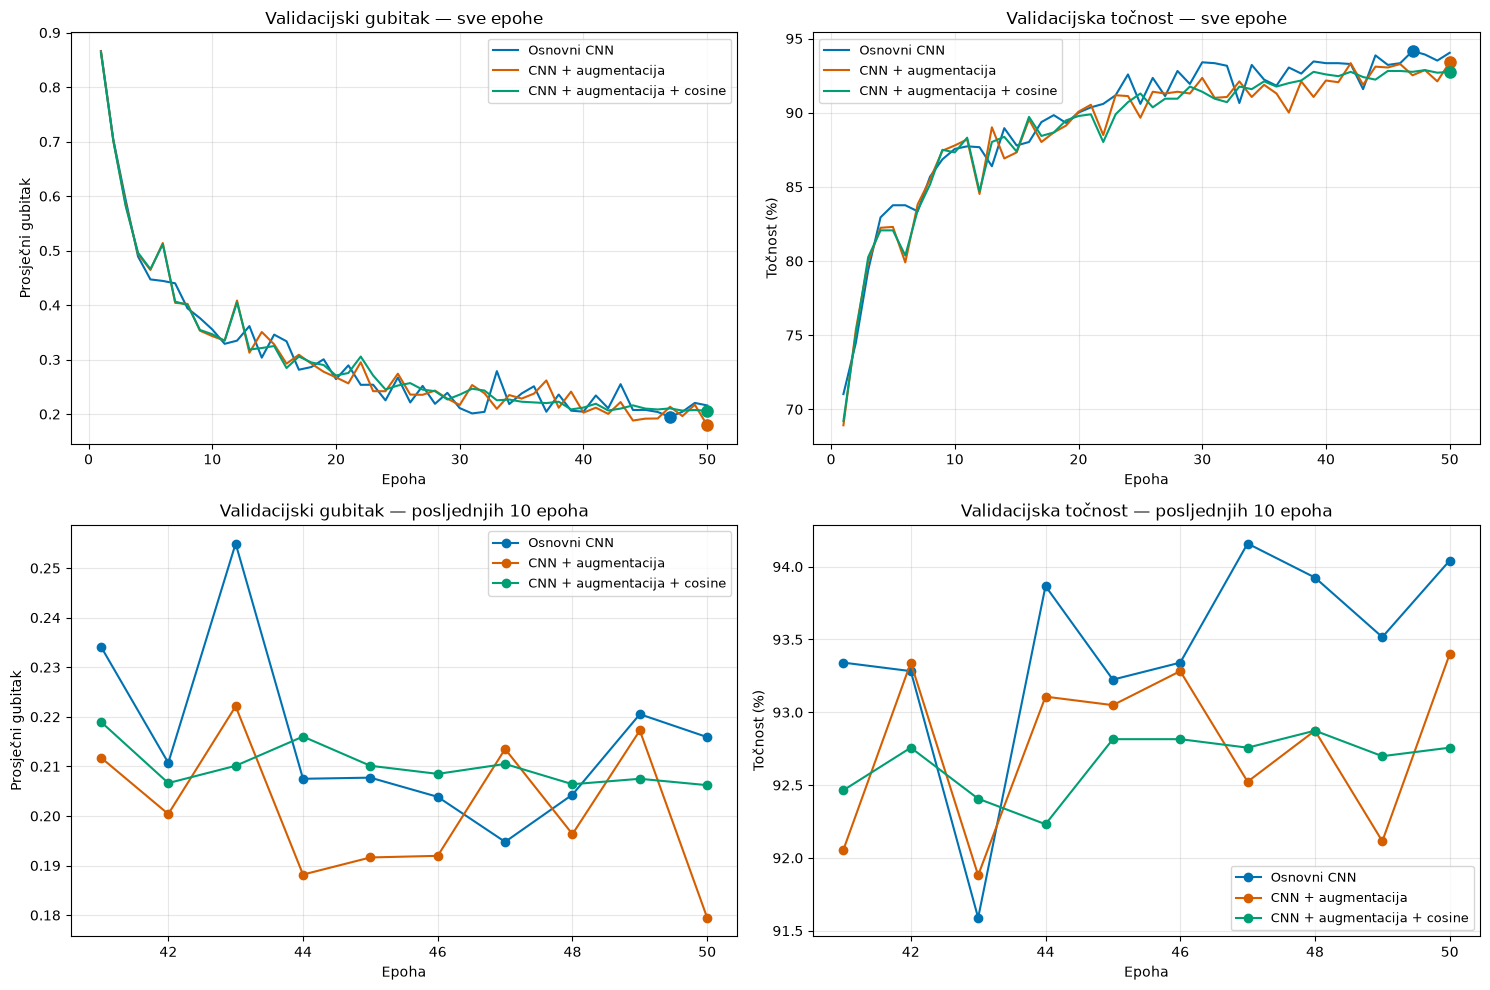

Model                             Najbolja epoha    Val. gubitak    Val. točnost
--------------------------------------------------------------------------------
Osnovni CNN                                   47          0.1948         94.16%
CNN + augmentacija                            50          0.1795         93.40%
CNN + augmentacija + cosine                   50          0.2062         92.76%


In [49]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Putanje do rezultata sva tri pokusa.
result_files = {
    "Osnovni CNN": (
        results_dir / "osnovni_cnn_model" / "rezultati.json"
    ),
    "CNN + augmentacija": (
        results_dir / "rezultati_augmentacija.json"
    ),
    "CNN + augmentacija + cosine": (
        results_dir / "rezultati_augmentacija_cosine.json"
    )
}

experiments = {}

for name, path in result_files.items():
    with open(path, "r", encoding="utf-8") as file:
        experiments[name] = json.load(file)

# Gornji red prikazuje sve epohe,
# donji red približava posljednjih 10 epoha svakog pokusa.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

colors = ["#0072B2", "#D55E00", "#009E73"]

for (name, results), color in zip(experiments.items(), colors):
    h = results["history"]

    epochs = np.arange(1, len(h["val_loss"]) + 1)
    val_loss = np.array(h["val_loss"])
    val_accuracy = np.array(h["val_accuracy"]) * 100

    best_epoch_number = results["best_epoch"]
    best_index = best_epoch_number - 1

    # Sve epohe.
    axes[0, 0].plot(epochs, val_loss, label=name, color=color)
    axes[0, 1].plot(epochs, val_accuracy, label=name, color=color)

    # Označavamo epohu odabranu prema najmanjem val. gubitku.
    axes[0, 0].scatter(
        best_epoch_number, val_loss[best_index],
        color=color, s=65, zorder=3
    )
    axes[0, 1].scatter(
        best_epoch_number, val_accuracy[best_index],
        color=color, s=65, zorder=3
    )

    # Posljednjih 10 epoha.
    axes[1, 0].plot(
        epochs[-10:], val_loss[-10:],
        marker="o", label=name, color=color
    )
    axes[1, 1].plot(
        epochs[-10:], val_accuracy[-10:],
        marker="o", label=name, color=color
    )

axes[0, 0].set_title("Validacijski gubitak — sve epohe")
axes[0, 1].set_title("Validacijska točnost — sve epohe")
axes[1, 0].set_title("Validacijski gubitak — posljednjih 10 epoha")
axes[1, 1].set_title("Validacijska točnost — posljednjih 10 epoha")

for row in range(2):
    axes[row, 0].set_ylabel("Prosječni gubitak")
    axes[row, 1].set_ylabel("Točnost (%)")

for ax in axes.flat:
    ax.set_xlabel("Epoha")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()

fig.savefig(
    results_dir / "usporedba_tri_pokusa.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Usporedba najboljih spremljenih modela sva tri pokusa.
print(
    f"{'Model':<32}"
    f"{'Najbolja epoha':>16}"
    f"{'Val. gubitak':>16}"
    f"{'Val. točnost':>16}"
)
print("-" * 80)

for name, results in experiments.items():
    best_index = results["best_epoch"] - 1
    h = results["history"]

    print(
        f"{name:<32}"
        f"{results['best_epoch']:>16}"
        f"{h['val_loss'][best_index]:>16.4f}"
        f"{h['val_accuracy'][best_index]:>15.2%}"
    )

In [50]:
# ČETVRTI POKUS: CNN + BatchNorm
# Bez augmentacije, uz stalnu stopu učenja.

# Vraćamo pripremu podataka kao u osnovnom pokusu.
basic_transform = transforms.ToTensor()

train_dataset.transform = basic_transform
val_dataset.transform = basic_transform
test_dataset.transform = basic_transform


class BloodCNNBatchNorm(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Stvaramo novi model od početka.
torch.manual_seed(42)

model = BloodCNNBatchNorm(num_classes=n_classes).to(device)

criterion = nn.CrossEntropyLoss()
learning_rate = 0.001

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Zadržavamo broj epoha osnovnog pokusa.
num_epochs = baseline_results["num_epochs"]

# U ovom pokusu nema prilagodbe stope učenja.
scheduler = None

num_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(model)
print(f"\nBroj parametara koji se uče: {num_parameters:,}")
print("Uređaj:", next(model.parameters()).device)
print("Broj epoha:", num_epochs)
print("Stopa učenja:", learning_rate)
print("Trening transformacija:", train_dataset.transform)

BloodCNNBatchNorm(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)

Broj parametara koji se uče: 207,048
Uređaj: cuda:0
Broj epoha: 50
Stopa učenja: 0.001
Trening transformacija: ToTensor()


In [51]:
import time
import json

best_model_path = results_dir / "bloodcnn_batchnorm_best.pt"

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "epoch_seconds": []
}

best_val_loss = float("inf")
best_epoch = 0

print(f"Broj epoha: {num_epochs}")
print(f"Stalna stopa učenja: {learning_rate}")
print("Trening transformacija:", train_dataset.transform)

for epoch in range(1, num_epochs + 1):
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    # train_one_epoch uključuje model.train():
    # BatchNorm koristi statistike trenutačnog batcha.
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # evaluate uključuje model.eval():
    # BatchNorm koristi statistike prikupljene tijekom treniranja.
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["epoch_seconds"].append(elapsed)

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch

        # state_dict sprema parametre i BatchNorm statistike.
        torch.save(model.state_dict(), best_model_path)

    status = " | spremljen najbolji model" if improved else ""

    print(
        f"Epoha {epoch:02d}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.2%} | "
        f"val acc: {val_accuracy:.2%} | "
        f"{elapsed:.1f} s"
        f"{status}",
        flush=True
    )

# Vraćamo najbolji model prema validacijskom gubitku.
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

batchnorm_results = {
    "history": history,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "num_epochs": num_epochs,
    "batch_size": train_loader.batch_size,
    "learning_rate": learning_rate,
    "augmentation": False,
    "batchnorm": True,
    "scheduler": None,
    "model_architecture": str(model),
    "pytorch_version": str(torch.__version__)
}

with open(
    results_dir / "rezultati_batchnorm.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        batchnorm_results,
        file,
        ensure_ascii=False,
        indent=2
    )

print(f"\nNajbolja epoha: {best_epoch}")
print(f"Najmanji validacijski gubitak: {best_val_loss:.4f}")
print(
    "Validacijska točnost te epohe:",
    f"{history['val_accuracy'][best_epoch - 1]:.2%}"
)
print("Najbolji model spremljen u:", best_model_path)

Broj epoha: 50
Stalna stopa učenja: 0.001
Trening transformacija: ToTensor()
Epoha 01/50 | train loss: 0.6465 | val loss: 0.4666 | train acc: 76.70% | val acc: 83.64% | 2.8 s | spremljen najbolji model
Epoha 02/50 | train loss: 0.3309 | val loss: 0.3032 | train acc: 88.17% | val acc: 90.01% | 2.1 s | spremljen najbolji model
Epoha 03/50 | train loss: 0.2642 | val loss: 0.3174 | train acc: 90.79% | val acc: 88.61% | 2.3 s
Epoha 04/50 | train loss: 0.2263 | val loss: 0.2678 | train acc: 91.98% | val acc: 90.13% | 2.3 s | spremljen najbolji model
Epoha 05/50 | train loss: 0.1874 | val loss: 0.3078 | train acc: 93.45% | val acc: 88.90% | 2.5 s
Epoha 06/50 | train loss: 0.1524 | val loss: 0.2586 | train acc: 94.81% | val acc: 91.76% | 2.5 s | spremljen najbolji model
Epoha 07/50 | train loss: 0.1476 | val loss: 0.3129 | train acc: 94.76% | val acc: 89.19% | 3.7 s
Epoha 08/50 | train loss: 0.1272 | val loss: 0.2771 | train acc: 95.43% | val acc: 90.60% | 5.2 s
Epoha 09/50 | train loss: 0.105

In [52]:
# PETI POKUS: CNN + BatchNorm + Dropout

# Ista priprema slika kao u četvrtom pokusu.
basic_transform = transforms.ToTensor()

train_dataset.transform = basic_transform
val_dataset.transform = basic_transform
test_dataset.transform = basic_transform


class BloodCNNBatchNormDropout(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            # Tijekom treniranja nasumično poništava
            # 30 % ulaznih značajki potpuno povezanog sloja.
            nn.Dropout(p=0.3),

            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Novi model i optimizator: treniranje počinje od početka.
torch.manual_seed(42)

model = BloodCNNBatchNormDropout(
    num_classes=n_classes
).to(device)

criterion = nn.CrossEntropyLoss()
learning_rate = 0.001

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

num_epochs = batchnorm_results["num_epochs"]
scheduler = None

print(model)
print("\nBroj epoha:", num_epochs)
print("Stopa učenja:", learning_rate)
print("Dropout: 0.3")
print("Uređaj:", next(model.parameters()).device)
print("Trening transformacija:", train_dataset.transform)

BloodCNNBatchNormDropout(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=1568, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)

Broj epoha: 50
Stopa učenja: 0.001
Dropout: 0.3
Uređaj: cuda:0
Trening transformacija: ToTensor()


In [53]:
import time
import json

best_model_path = results_dir / "bloodcnn_batchnorm_dropout_best.pt"

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "epoch_seconds": []
}

best_val_loss = float("inf")
best_epoch = 0

print(f"Broj epoha: {num_epochs}")
print(f"Stalna stopa učenja: {learning_rate}")
print("Dropout: 0.3")
print("Trening transformacija:", train_dataset.transform)

for epoch in range(1, num_epochs + 1):
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    # model.train() unutar funkcije uključuje Dropout.
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # model.eval() unutar funkcije isključuje Dropout.
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["epoch_seconds"].append(elapsed)

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), best_model_path)

    status = " | spremljen najbolji model" if improved else ""

    print(
        f"Epoha {epoch:02d}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.2%} | "
        f"val acc: {val_accuracy:.2%} | "
        f"{elapsed:.1f} s"
        f"{status}",
        flush=True
    )

# Vraćamo težine s najmanjim validacijskim gubitkom.
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

dropout_results = {
    "history": history,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "num_epochs": num_epochs,
    "batch_size": train_loader.batch_size,
    "learning_rate": learning_rate,
    "augmentation": False,
    "batchnorm": True,
    "dropout": 0.3,
    "scheduler": None,
    "model_architecture": str(model),
    "pytorch_version": str(torch.__version__)
}

with open(
    results_dir / "rezultati_batchnorm_dropout.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        dropout_results,
        file,
        ensure_ascii=False,
        indent=2
    )

print(f"\nNajbolja epoha: {best_epoch}")
print(f"Najmanji validacijski gubitak: {best_val_loss:.4f}")
print(
    "Validacijska točnost te epohe:",
    f"{history['val_accuracy'][best_epoch - 1]:.2%}"
)
print("Najbolji model spremljen u:", best_model_path)

Broj epoha: 50
Stalna stopa učenja: 0.001
Dropout: 0.3
Trening transformacija: ToTensor()
Epoha 01/50 | train loss: 0.6808 | val loss: 0.4462 | train acc: 75.05% | val acc: 84.00% | 2.7 s | spremljen najbolji model
Epoha 02/50 | train loss: 0.3752 | val loss: 0.4278 | train acc: 86.55% | val acc: 84.70% | 2.7 s | spremljen najbolji model
Epoha 03/50 | train loss: 0.3159 | val loss: 0.3054 | train acc: 88.75% | val acc: 89.72% | 2.3 s | spremljen najbolji model
Epoha 04/50 | train loss: 0.2804 | val loss: 0.2713 | train acc: 90.03% | val acc: 90.71% | 2.6 s | spremljen najbolji model
Epoha 05/50 | train loss: 0.2517 | val loss: 0.3150 | train acc: 90.99% | val acc: 88.14% | 4.8 s
Epoha 06/50 | train loss: 0.2237 | val loss: 0.2464 | train acc: 91.78% | val acc: 91.71% | 3.9 s | spremljen najbolji model
Epoha 07/50 | train loss: 0.2097 | val loss: 0.2502 | train acc: 92.27% | val acc: 91.41% | 3.5 s
Epoha 08/50 | train loss: 0.1981 | val loss: 0.2248 | train acc: 92.84% | val acc: 92.11%

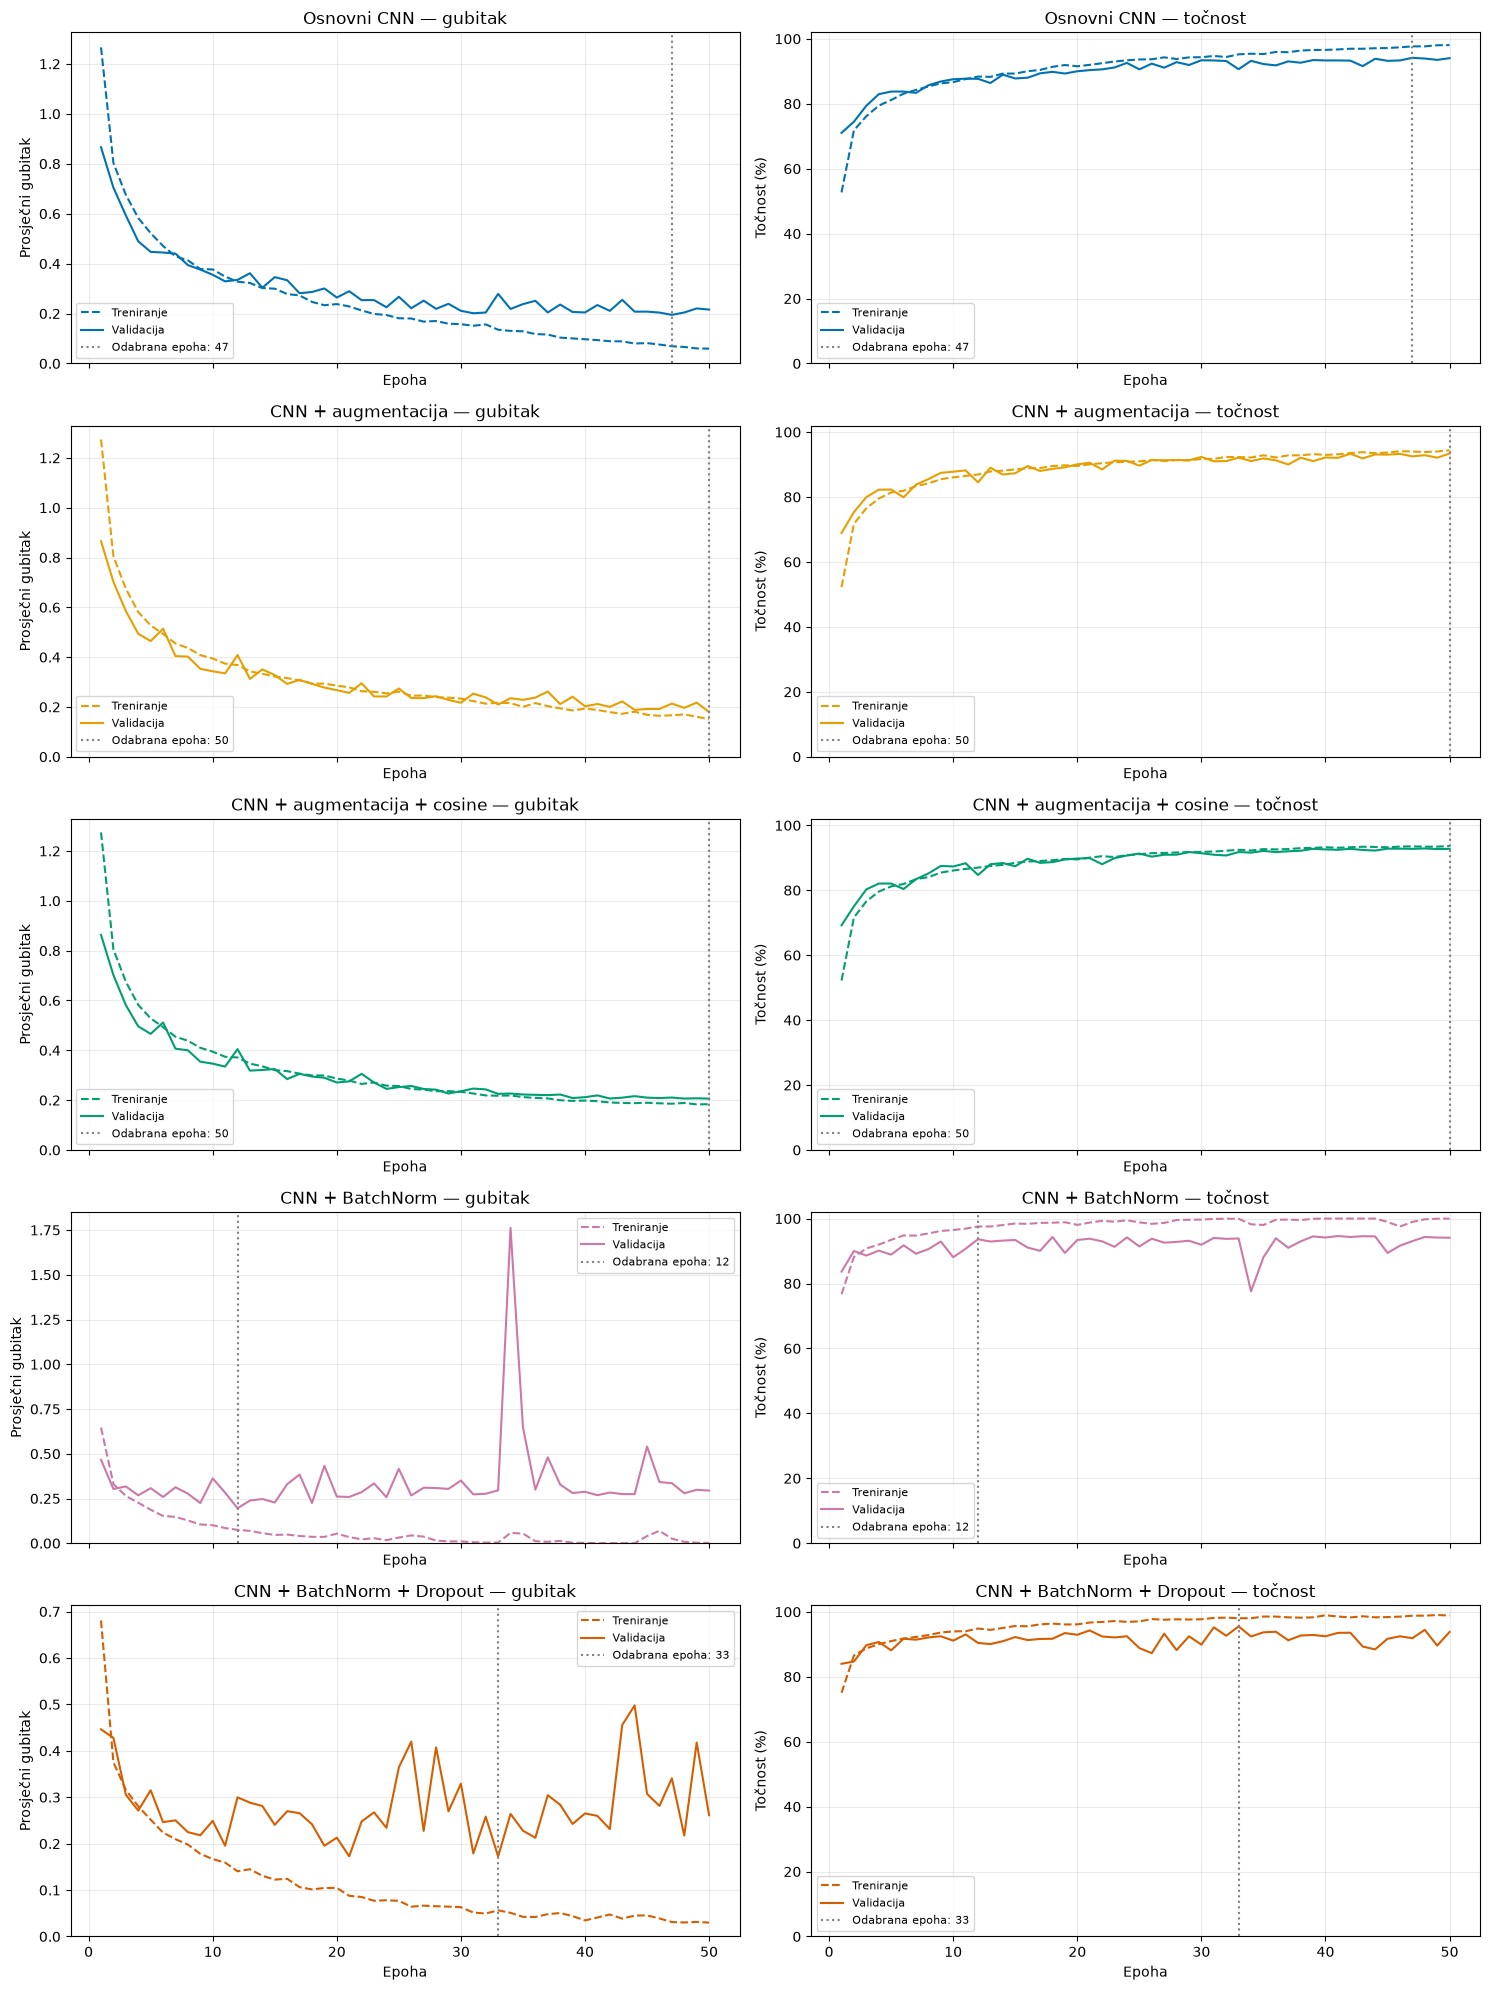

In [54]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Spremljeni rezultati svih pet pokusa.
result_files = {
    "Osnovni CNN":
        results_dir / "osnovni_cnn_model" / "rezultati.json",

    "CNN + augmentacija":
        results_dir / "rezultati_augmentacija.json",

    "CNN + augmentacija + cosine":
        results_dir / "rezultati_augmentacija_cosine.json",

    "CNN + BatchNorm":
        results_dir / "rezultati_batchnorm.json",

    "CNN + BatchNorm + Dropout":
        results_dir / "rezultati_batchnorm_dropout.json"
}

experiments = {}

for name, path in result_files.items():
    with open(path, "r", encoding="utf-8") as file:
        experiments[name] = json.load(file)

colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]

# Svaki red prikazuje jedan pokus:
# lijevo gubitak, desno točnost.
fig, axes = plt.subplots(
    nrows=len(experiments),
    ncols=2,
    figsize=(15, 20),
    sharex=True
)

for row, ((name, results), color) in enumerate(
    zip(experiments.items(), colors)
):
    h = results["history"]
    epochs = np.arange(1, len(h["train_loss"]) + 1)
    best_epoch_number = results["best_epoch"]

    # Gubitak na treningu i validaciji.
    axes[row, 0].plot(
        epochs, h["train_loss"],
        label="Treniranje", color=color, linestyle="--"
    )
    axes[row, 0].plot(
        epochs, h["val_loss"],
        label="Validacija", color=color
    )
    axes[row, 0].set_title(f"{name} — gubitak")
    axes[row, 0].set_ylabel("Prosječni gubitak")
    axes[row, 0].set_ylim(bottom=0)

    # Točnost na treningu i validaciji.
    axes[row, 1].plot(
        epochs, np.array(h["train_accuracy"]) * 100,
        label="Treniranje", color=color, linestyle="--"
    )
    axes[row, 1].plot(
        epochs, np.array(h["val_accuracy"]) * 100,
        label="Validacija", color=color
    )
    axes[row, 1].set_title(f"{name} — točnost")
    axes[row, 1].set_ylabel("Točnost (%)")
    axes[row, 1].set_ylim(0, 102)

    for ax in axes[row]:
        ax.axvline(
            best_epoch_number,
            color="gray",
            linestyle=":",
            label=f"Odabrana epoha: {best_epoch_number}"
        )
        ax.set_xlabel("Epoha")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

plt.tight_layout()
fig.savefig(
    results_dir / "svih_pet_pokusa_tijek.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

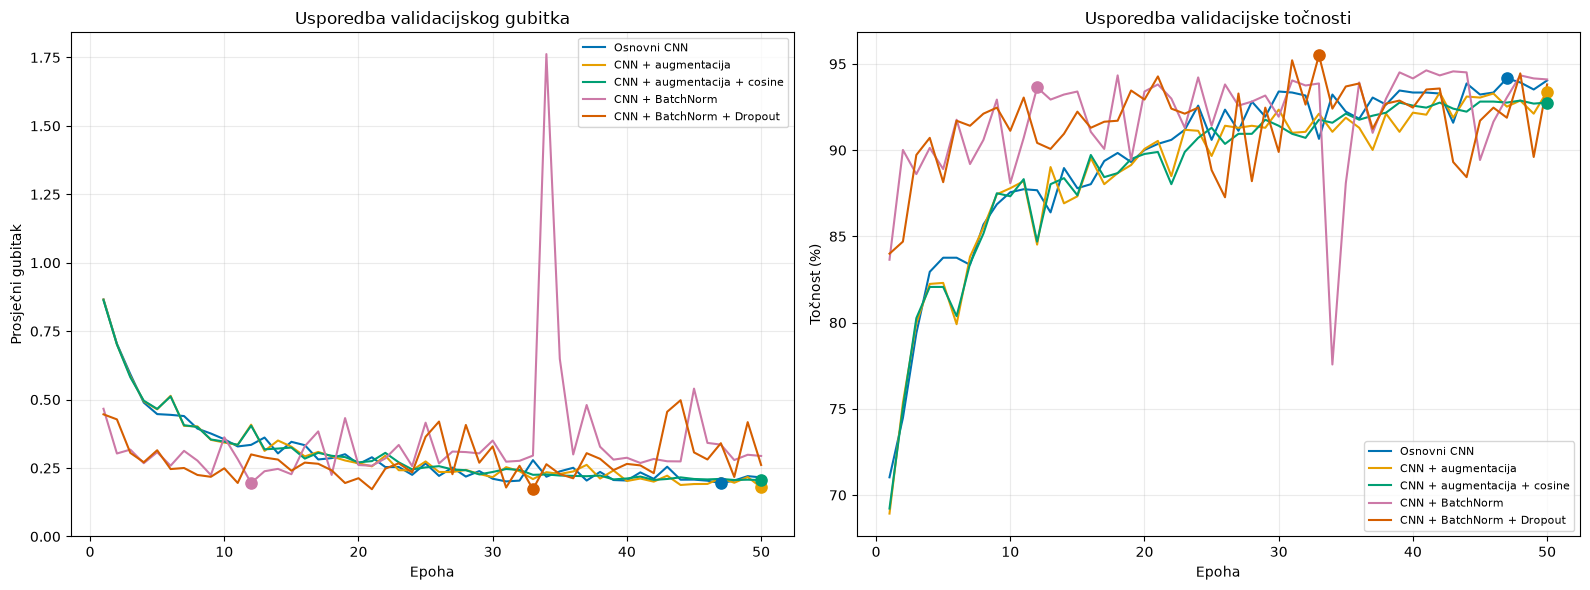

Model                               Najbolja epoha    Val. gubitak    Val. točnost
----------------------------------------------------------------------------------
Osnovni CNN                                     47          0.1948         94.16%
CNN + augmentacija                              50          0.1795         93.40%
CNN + augmentacija + cosine                     50          0.2062         92.76%
CNN + BatchNorm                                 12          0.1955         93.63%
CNN + BatchNorm + Dropout                       33          0.1725         95.50%


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for (name, results), color in zip(experiments.items(), colors):
    h = results["history"]
    epochs = np.arange(1, len(h["val_loss"]) + 1)

    best_epoch_number = results["best_epoch"]
    best_index = best_epoch_number - 1

    # Validacijski gubitak.
    axes[0].plot(
        epochs,
        h["val_loss"],
        label=name,
        color=color
    )
    axes[0].scatter(
        best_epoch_number,
        h["val_loss"][best_index],
        color=color,
        s=65,
        zorder=3
    )

    # Validacijska točnost u postocima.
    val_accuracy_percent = np.array(h["val_accuracy"]) * 100

    axes[1].plot(
        epochs,
        val_accuracy_percent,
        label=name,
        color=color
    )
    axes[1].scatter(
        best_epoch_number,
        val_accuracy_percent[best_index],
        color=color,
        s=65,
        zorder=3
    )

axes[0].set_title("Usporedba validacijskog gubitka")
axes[0].set_ylabel("Prosječni gubitak")
axes[0].set_ylim(bottom=0)

axes[1].set_title("Usporedba validacijske točnosti")
axes[1].set_ylabel("Točnost (%)")

for ax in axes:
    ax.set_xlabel("Epoha")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()

fig.savefig(
    results_dir / "usporedba_pet_modela_validacija.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Tablica rezultata odabranih modela.
print(
    f"{'Model':<34}"
    f"{'Najbolja epoha':>16}"
    f"{'Val. gubitak':>16}"
    f"{'Val. točnost':>16}"
)
print("-" * 82)

for name, results in experiments.items():
    best_index = results["best_epoch"] - 1
    h = results["history"]

    print(
        f"{name:<34}"
        f"{results['best_epoch']:>16}"
        f"{h['val_loss'][best_index]:>16.4f}"
        f"{h['val_accuracy'][best_index]:>15.2%}"
    )

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# Testne slike koristimo bez augmentacije.
test_dataset.transform = transforms.ToTensor()

# Stvaramo odgovarajuću arhitekturu i učitavamo najbolje težine.
final_model = BloodCNNBatchNormDropout(
    num_classes=n_classes
).to(device)

final_model_path = (
    results_dir / "bloodcnn_batchnorm_dropout_best.pt"
)

final_model.load_state_dict(
    torch.load(
        final_model_path,
        map_location=device,
        weights_only=True
    )
)

# Isključuje Dropout i postavlja BatchNorm u evaluacijski način.
final_model.eval()

all_true_labels = []
all_predictions = []

total_test_loss = 0.0
total_test_samples = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        outputs = final_model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        current_batch_size = images.size(0)
        total_test_loss += loss.item() * current_batch_size
        total_test_samples += current_batch_size

        all_true_labels.append(labels.cpu().numpy())
        all_predictions.append(predictions.cpu().numpy())

# Spajamo rezultate svih batcheva u dva niza.
y_true = np.concatenate(all_true_labels)
y_pred = np.concatenate(all_predictions)

test_loss = total_test_loss / total_test_samples
test_accuracy = accuracy_score(y_true, y_pred)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(n_classes),
        average="macro",
        zero_division=0
    )
)

print("REZULTATI NA TESTNOM SKUPU")
print("Broj slika:", total_test_samples)
print(f"Gubitak:         {test_loss:.4f}")
print(f"Točnost:         {test_accuracy:.2%}")
print(f"Macro preciznost:{macro_precision: .2%}")
print(f"Macro odziv:     {macro_recall:.2%}")
print(f"Macro F1:        {macro_f1:.2%}")

print("\nREZULTATI PO KLASAMA")
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(n_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Spremamo metrike i predviđanja za daljnju analizu.
test_results = {
    "model": "CNN + BatchNorm + Dropout",
    "checkpoint": str(final_model_path),
    "num_test_samples": total_test_samples,
    "test_loss": test_loss,
    "accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "classification_report": classification_report(
        y_true,
        y_pred,
        labels=np.arange(n_classes),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
}

with open(
    results_dir / "test_rezultati_finalnog_modela.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(test_results, file, ensure_ascii=False, indent=2)

np.savez(
    results_dir / "test_predvidanja.npz",
    y_true=y_true,
    y_pred=y_pred
)

REZULTATI NA TESTNOM SKUPU
Broj slika: 3421
Gubitak:         0.2136
Točnost:         93.98%
Macro preciznost: 93.31%
Macro odziv:     93.52%
Macro F1:        93.38%

REZULTATI PO KLASAMA
                                                                     precision    recall  f1-score   support

                                                           basophil     0.9286    0.9057    0.9170       244
                                                         eosinophil     0.9872    0.9904    0.9888       624
                                                       erythroblast     0.9521    0.9582    0.9551       311
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)     0.8484    0.8895    0.8685       579
                                                         lymphocyte     0.8842    0.9424    0.9124       243
                                                           monocyte     0.8821    0.8697    0.8759       284
                                                 

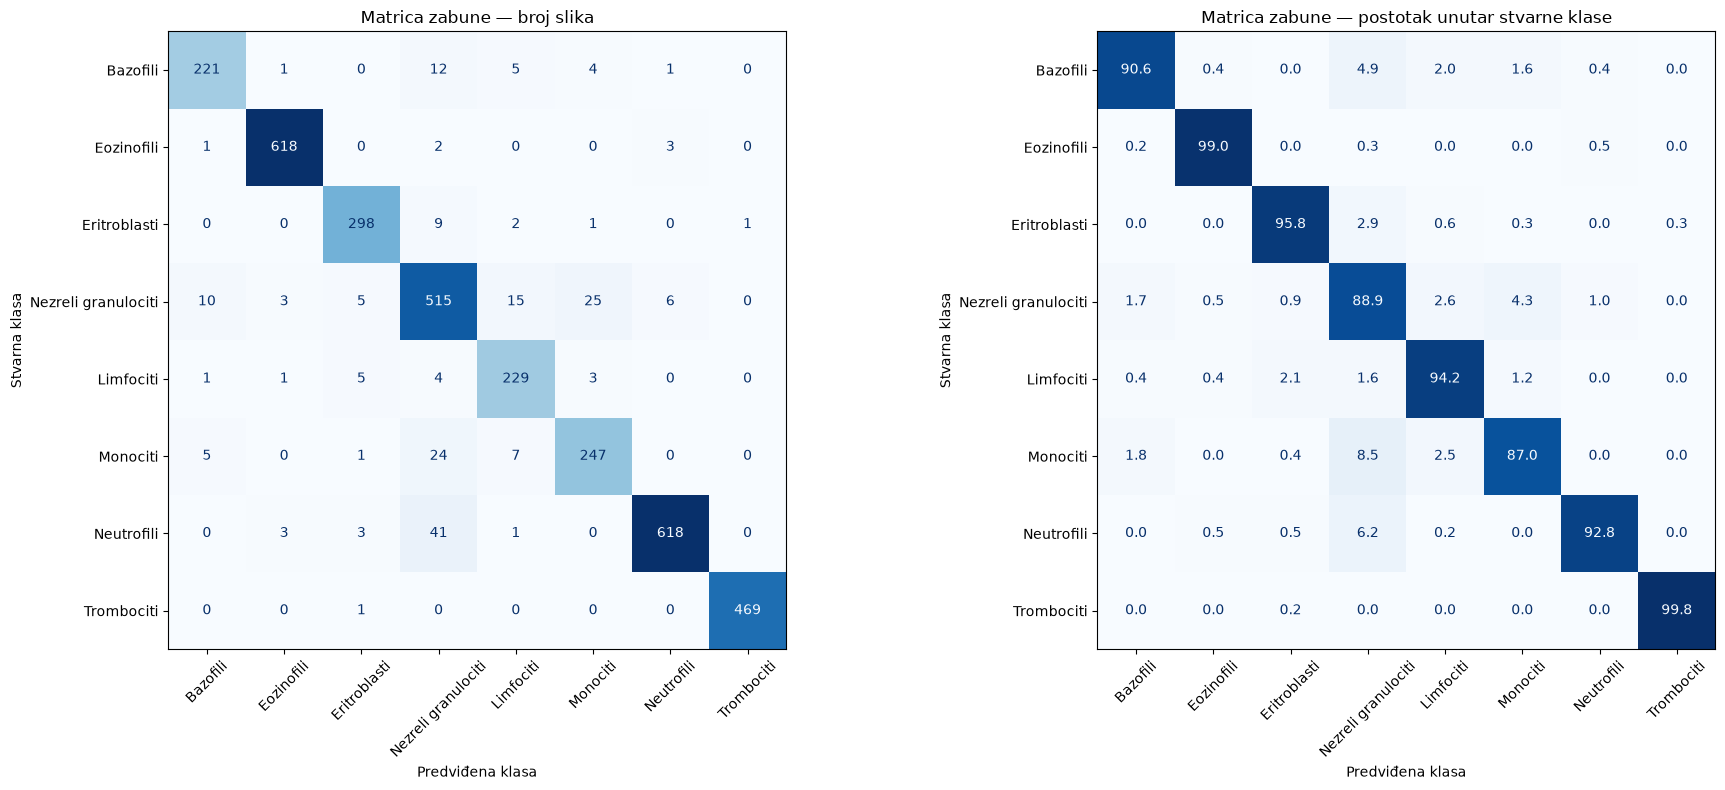

Najčešće zamjene klasa:
Neutrofili → Nezreli granulociti: 41 slika
Nezreli granulociti → Monociti: 25 slika
Monociti → Nezreli granulociti: 24 slika
Nezreli granulociti → Limfociti: 15 slika
Bazofili → Nezreli granulociti: 12 slika

Ispravno klasificirano: 3215
Pogrešno klasificirano: 206


In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Kraći nazivi za čitljivost grafova.
display_names = [
    "Bazofili",
    "Eozinofili",
    "Eritroblasti",
    "Nezreli granulociti",
    "Limfociti",
    "Monociti",
    "Neutrofili",
    "Trombociti"
]

class_ids = np.arange(n_classes)

# Broj slika za svaku kombinaciju stvarne i predviđene klase.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids
)

# Normalizacija po stvarnim klasama:
# svaki red pokazuje udjele predviđanja za tu stvarnu klasu.
cm_percent = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
    normalize="true"
) * 100

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_names
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    xticks_rotation=45
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_percent,
    display_labels=display_names
).plot(
    ax=axes[1],
    cmap="Blues",
    values_format=".1f",
    colorbar=False,
    xticks_rotation=45
)

axes[0].set_title("Matrica zabune — broj slika")
axes[1].set_title("Matrica zabune — postotak unutar stvarne klase")

# Jednaka skala od 0 do 100 za postotke.
axes[1].images[0].set_clim(0, 100)

for ax in axes:
    ax.set_xlabel("Predviđena klasa")
    ax.set_ylabel("Stvarna klasa")

plt.tight_layout()

fig.savefig(
    results_dir / "matrica_zabune_test.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Ispisujemo pet najčešćih vrsta pogreške.
errors = [
    (cm[true_id, predicted_id], true_id, predicted_id)
    for true_id in class_ids
    for predicted_id in class_ids
    if true_id != predicted_id and cm[true_id, predicted_id] > 0
]

errors.sort(key=lambda item: item[0], reverse=True)

print("Najčešće zamjene klasa:")
for count, true_id, predicted_id in errors[:5]:
    print(
        f"{display_names[true_id]} → "
        f"{display_names[predicted_id]}: {count} slika"
    )

print(f"\nIspravno klasificirano: {np.trace(cm)}")
print(f"Pogrešno klasificirano: {cm.sum() - np.trace(cm)}")

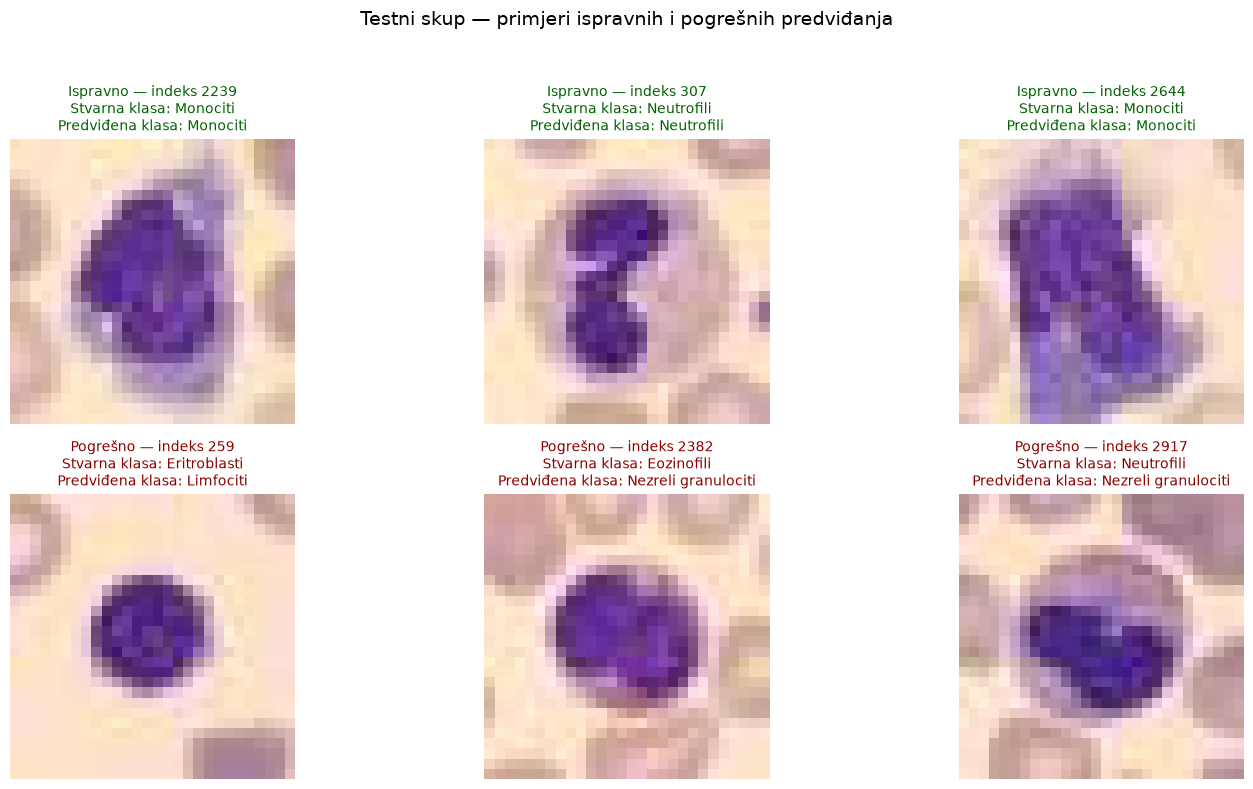

In [58]:
# Predviđanja odgovaraju redoslijedu testnih slika jer smo
# test_loader napravili sa shuffle=False.
assert len(y_true) == len(test_dataset)
assert np.array_equal(y_true, test_dataset.labels.flatten())

correct_indices = np.flatnonzero(y_true == y_pred)
incorrect_indices = np.flatnonzero(y_true != y_pred)

# Ponovljiv nasumični izbor primjera, bez ručnog biranja.
rng = np.random.default_rng(seed=42)

selected_correct = rng.choice(
    correct_indices, size=3, replace=False
)
selected_incorrect = rng.choice(
    incorrect_indices, size=3, replace=False
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

groups = [
    ("Ispravno", selected_correct, "darkgreen"),
    ("Pogrešno", selected_incorrect, "darkred")
]

for row, (status, indices, color) in enumerate(groups):
    for column, image_index in enumerate(indices):
        ax = axes[row, column]

        true_name = display_names[int(y_true[image_index])]
        predicted_name = display_names[int(y_pred[image_index])]

        ax.imshow(test_dataset.imgs[image_index])
        ax.set_title(
            f"{status} — indeks {image_index}\n"
            f"Stvarna klasa: {true_name}\n"
            f"Predviđena klasa: {predicted_name}",
            color=color,
            fontsize=10
        )
        ax.axis("off")

fig.suptitle(
    "Testni skup — primjeri ispravnih i pogrešnih predviđanja",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    results_dir / "primjeri_testnih_predvidanja.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [2]:
# USPOREDBA INFERENCIJE: BATCH 1 I BATCH 64

import copy
import time
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torchvision import transforms
from medmnist import BloodMNIST

# Putanja do projekta i prethodno spremljenog modela.
project_dir = Path(
    r"C:\Users\PC\Documents\ferit\DRB_2g\DUBOKO UČENJE\LV1"
)
results_dir = project_dir / "rezultati"
model_path = results_dir / "bloodcnn_batchnorm_dropout_best.pt"

if not model_path.is_file():
    raise FileNotFoundError(
        f"Nije pronađen spremljeni model: {model_path}"
    )

# Ista arhitektura kao u petom pokusu.
class BloodCNNBatchNormDropout(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Učitavamo naučene težine — ne treniramo ponovno.
benchmark_model = BloodCNNBatchNormDropout()

benchmark_model.load_state_dict(
    torch.load(
        model_path,
        map_location="cpu",
        weights_only=True
    )
)
benchmark_model.eval()

# Učitavamo postojeće testne podatke bez augmentacije.
benchmark_dataset = BloodMNIST(
    split="test",
    root=str(project_dir / "podaci"),
    size=28,
    transform=transforms.ToTensor(),
    download=False
)

# Iste slike koristimo za CPU i GPU.
comparison_images = torch.stack([
    benchmark_dataset[i][0]
    for i in range(64)
])


def measure_inference(model, inputs, target_device,
                      warmup=30, repetitions=200):
    measured_model = copy.deepcopy(model).to(target_device)
    measured_model.eval()

    # Prijenos podataka nije uključen u mjerenje.
    device_inputs = inputs.to(target_device)

    def synchronize():
        if target_device.type == "cuda":
            torch.cuda.synchronize(target_device)

    times_ms = []

    with torch.inference_mode():
        # Zagrijavanje.
        for _ in range(warmup):
            measured_model(device_inputs)

        synchronize()

        for _ in range(repetitions):
            synchronize()
            start = time.perf_counter()

            measured_model(device_inputs)

            synchronize()
            times_ms.append(
                (time.perf_counter() - start) * 1000
            )

    del measured_model, device_inputs

    return {
        "mean_ms": float(np.mean(times_ms)),
        "median_ms": float(np.median(times_ms)),
        "std_ms": float(np.std(times_ms))
    }


devices_to_compare = {"CPU": torch.device("cpu")}

if torch.cuda.is_available():
    devices_to_compare["GPU"] = torch.device("cuda:0")

warmup = 30
repetitions = 200
batch_comparison = []

for batch_size_to_test in [1, 64]:
    inputs = comparison_images[:batch_size_to_test]

    for device_name, target_device in devices_to_compare.items():
        print(
            f"Mjerim: {device_name}, batch {batch_size_to_test}...",
            flush=True
        )

        timing = measure_inference(
            benchmark_model,
            inputs,
            target_device,
            warmup=warmup,
            repetitions=repetitions
        )

        mean_batch_ms = timing["mean_ms"]

        batch_comparison.append({
            "device": device_name,
            "batch_size": batch_size_to_test,
            "mean_batch_ms": mean_batch_ms,
            "median_batch_ms": timing["median_ms"],
            "std_batch_ms": timing["std_ms"],
            "mean_ms_per_image": (
                mean_batch_ms / batch_size_to_test
            ),
            "images_per_second": (
                batch_size_to_test * 1000 / mean_batch_ms
            )
        })

print("\nUSPOREDBA VREMENA INFERENCIJE")
print(
    f"{'Uređaj':<10}"
    f"{'Batch':>8}"
    f"{'Prosjek/batch (ms)':>22}"
    f"{'Prosjek/slika (ms)':>22}"
    f"{'Slika/s':>14}"
)
print("-" * 76)

for result in batch_comparison:
    print(
        f"{result['device']:<10}"
        f"{result['batch_size']:>8}"
        f"{result['mean_batch_ms']:>22.4f}"
        f"{result['mean_ms_per_image']:>22.4f}"
        f"{result['images_per_second']:>14.1f}"
    )

comparison_path = results_dir / "inferencija_batch_1_i_64.json"

with open(comparison_path, "w", encoding="utf-8") as file:
    json.dump(
        {
            "model_path": str(model_path),
            "warmup": warmup,
            "repetitions": repetitions,
            "includes_preprocessing": False,
            "includes_cpu_gpu_transfer": False,
            "cpu_threads": torch.get_num_threads(),
            "results": batch_comparison
        },
        file,
        ensure_ascii=False,
        indent=2
    )

print("\nRezultati spremljeni u:", comparison_path)

Mjerim: CPU, batch 1...
Mjerim: GPU, batch 1...
Mjerim: CPU, batch 64...
Mjerim: GPU, batch 64...

USPOREDBA VREMENA INFERENCIJE
Uređaj       Batch    Prosjek/batch (ms)    Prosjek/slika (ms)       Slika/s
----------------------------------------------------------------------------
CPU              1                0.7039                0.7039        1420.7
GPU              1                0.9415                0.9415        1062.1
CPU             64                7.7081                0.1204        8303.0
GPU             64                0.9503                0.0148       67348.7

Rezultati spremljeni u: C:\Users\PC\Documents\ferit\DRB_2g\DUBOKO UČENJE\LV1\rezultati\inferencija_batch_1_i_64.json


In [3]:
# MEMORIJSKI OTISAK KONAČNOG MODELA

import json

if "benchmark_model" not in globals() or "model_path" not in globals():
    raise RuntimeError(
        "Prvo pokreni prethodnu celiju: USPOREDBA INFERENCIJE: BATCH 1 I BATCH 64. "
        "Ona ucitava spremljeni model; ponovno treniranje nije potrebno."
    )


# Broj parametara mreže.
parameter_count = sum(
    parameter.numel()
    for parameter in benchmark_model.parameters()
)

# Memorija parametara:
# broj elemenata × broj bajtova po elementu.
parameter_bytes = sum(
    parameter.numel() * parameter.element_size()
    for parameter in benchmark_model.parameters()
)

# Memorija buffera, uključujući BatchNorm statistike.
buffer_bytes = sum(
    buffer.numel() * buffer.element_size()
    for buffer in benchmark_model.buffers()
)

total_bytes = parameter_bytes + buffer_bytes

# Veličina spremljene datoteke modela na disku.
checkpoint_bytes = model_path.stat().st_size

# Jedan MiB ima 1024 × 1024 bajta.
bytes_per_mib = 1024 ** 2

print("MEMORIJSKI OTISAK KONAČNOG MODELA")
print(f"Broj parametara: {parameter_count:,}")
print(f"Parametri: {parameter_bytes / bytes_per_mib:.4f} MiB")
print(f"Bufferi: {buffer_bytes / bytes_per_mib:.4f} MiB")
print(f"Parametri + bufferi: {total_bytes / bytes_per_mib:.4f} MiB")
print(
    f"Datoteka modela na disku: "
    f"{checkpoint_bytes / bytes_per_mib:.4f} MiB"
)

# Spremanje rezultata.
memory_results = {
    "parameter_count": parameter_count,
    "parameter_bytes": parameter_bytes,
    "buffer_bytes": buffer_bytes,
    "parameters_and_buffers_bytes": total_bytes,
    "checkpoint_bytes": checkpoint_bytes
}

output_path = results_dir / "memorijski_otisak.json"

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(memory_results, file, ensure_ascii=False, indent=2)

print("\nRezultati spremljeni u:", output_path)

MEMORIJSKI OTISAK KONAČNOG MODELA
Broj parametara: 207,048
Parametri: 0.7898 MiB
Bufferi: 0.0004 MiB
Parametri + bufferi: 0.7902 MiB
Datoteka modela na disku: 0.7961 MiB

Rezultati spremljeni u: C:\Users\PC\Documents\ferit\DRB_2g\DUBOKO UČENJE\LV1\rezultati\memorijski_otisak.json
